# Walk-forward validation — rolling 3-month train / 1-month test

`portfolio_hyperparam_sweep` found that on the most recent window the sweep winner
($K=40, \gamma=5$, +17.8%) was **not** seed luck (30-restart dispersion $\approx 0$) — but it
might still be *window* luck: one good September. This notebook answers that by rolling the
same 3m-train / 1m-test split backward over the cached 2 years of top-500 daily returns:

for each window $i$ (0 = most recent) and each $(\gamma, K)$:
1. fit on that window's 3 training months (best of `N_RESTARTS` by train objective —
   the production rule),
2. evaluate the frozen weights on that window's held-out month.

A configuration worth gambling on should be **consistently** near the top across windows —
high mean *and* high worst-month *and* a good mean rank — not a one-window wonder.

Restarts are set to 5 (not 30): the sweep notebook already proved restart dispersion is
$\approx 0$ at `lr=0.005`, so extra restarts buy nothing here and this notebook's axis of
uncertainty is *time*, not seeds. Runtime: ~6-7 min per window, ~40 min for the default
6-window 6×5 grid.

*Not financial advice; overlapping training windows make adjacent windows correlated (see
caveats).*

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from stonks import get_prices, to_returns
from stonks.portfolio import _factor_covariance, _optimize_long_only

%matplotlib inline

## Parameters

In [2]:
TOP_N = 500
TRAIN_MONTHS = 3
TEST_MONTHS = 1
PERIOD = "2y"       # cached source
N_WINDOWS = 6       # window 0 = the most recent (same as the sweep notebook)

GAMMAS = [5, 10, 20, 40, 80, 160]
KS = [3, 5, 10, 25, 40]

N_RESTARTS = 5      # restart dispersion proven ~0 at this lr; time is the axis here
LR = 0.005
ITERS = 8000
MIN_WEIGHT = 1e-3
SEED = 0

## Fetch prices once, build the rolling windows

Each window's universe is `dropna`-ed over its own 4 months (names entering/exiting the
top-500 are handled per window); train/test within a window always share the universe.

In [3]:
prices = get_prices(top_n=TOP_N, period=PERIOD, interval="1d", field="close")
last = pd.Timestamp(prices.columns[-1])


def make_window(i: int):
    """(train, test) returns frames for the i-th most recent 3m/1m window."""
    end = last + pd.Timedelta(days=1) - pd.DateOffset(months=i)      # exclusive right edge
    test_start = end - pd.DateOffset(months=TEST_MONTHS)
    train_start = test_start - pd.DateOffset(months=TRAIN_MONTHS)
    p_win = prices.loc[:, (prices.columns >= train_start) & (prices.columns < end)]
    r_win = to_returns(p_win).dropna()
    train = r_win.loc[:, r_win.columns < test_start]
    test = r_win.loc[:, r_win.columns >= test_start]
    if train.empty or test.empty:
        raise ValueError(f"window {i} is empty (train {train.shape[1]}d, test {test.shape[1]}d)")
    return train, test


windows = []
for i in range(N_WINDOWS):
    train, test = make_window(i)
    windows.append((train, test))
    print(f"window {i}: train {train.columns[0].date()}..{train.columns[-1].date()} "
          f"({train.shape[1]}d) | test {test.columns[0].date()}..{test.columns[-1].date()} "
          f"({test.shape[1]}d) | {train.shape[0]} tickers")

window 0: train 2026-06-23..2026-09-18 (62d) | test 2026-09-21..2026-10-20 (22d) | 499 tickers
window 1: train 2026-05-22..2026-08-20 (62d) | test 2026-08-21..2026-09-18 (20d) | 496 tickers
window 2: train 2026-04-22..2026-07-20 (61d) | test 2026-07-21..2026-08-20 (23d) | 495 tickers
window 3: train 2026-03-24..2026-06-18 (61d) | test 2026-06-22..2026-07-20 (20d) | 495 tickers
window 4: train 2026-02-24..2026-05-20 (61d) | test 2026-05-21..2026-06-18 (20d) | 494 tickers
window 5: train 2026-01-22..2026-04-20 (61d) | test 2026-04-21..2026-05-20 (22d) | 493 tickers


## Walk-forward sweep

Best-of-restarts on each window's training months, frozen weights on that window's test
month. 1/N is evaluated on every window with the same universe.

In [4]:
def perf(w, R):
    rp = w @ R
    profit = np.prod(1 + rp) - 1
    sharpe = rp.mean() / rp.std() * np.sqrt(252) if rp.std() > 0 else np.nan
    return profit, sharpe


def clean_full(w_raw, index):
    """min_weight cleanup + renormalize, zero-padded back to the full universe."""
    ws = pd.Series(w_raw, index=index)
    ws = ws[ws >= MIN_WEIGHT]
    ws = ws / ws.sum()
    return ws.reindex(index, fill_value=0.0).to_numpy()


profits = {(K, g): [] for K in KS for g in GAMMAS}
sharpes = {(K, g): [] for K in KS for g in GAMMAS}
bench_profits, bench_sharpes = [], []
t_start = time.time()

for i, (train, test) in enumerate(windows):
    te, tr = test.to_numpy(), train.to_numpy()
    w_1n = np.full(train.shape[0], 1.0 / train.shape[0])
    p, s = perf(w_1n, te)
    bench_profits.append(p)
    bench_sharpes.append(s)
    for K in KS:
        mu, Sigma = _factor_covariance(train, K)
        for gamma in GAMMAS:
            w_raw, _ = _optimize_long_only(
                mu, Sigma, gamma, iters=ITERS, lr=LR, seed=SEED, n_restarts=N_RESTARTS
            )
            p, s = perf(clean_full(w_raw, train.index), te)
            profits[(K, gamma)].append(p)
            sharpes[(K, gamma)].append(s)
    print(f"window {i} done (1/N {bench_profits[-1]:+.2%}) [{time.time() - t_start:6.0f}s elapsed]",
          flush=True)

labels = [f"w{i}" for i in range(N_WINDOWS)]
rows = []
for K in KS:
    for gamma in GAMMAS:
        rows.append({"K": K, "gamma": gamma, **dict(zip(labels, profits[(K, gamma)]))})
wf = pd.DataFrame(rows)
wf["mean"] = wf[labels].mean(axis=1)
wf["std"] = wf[labels].std(axis=1)
wf["min"] = wf[labels].min(axis=1)
wf["frac_pos"] = (wf[labels] > 0).mean(axis=1)
# mean rank across windows (1 = best each window)
ranks = pd.DataFrame({lbl: wf[lbl].rank(ascending=False) for lbl in labels})
wf["mean_rank"] = ranks.mean(axis=1)
wf["sharpe_mean"] = [np.mean(sharpes[(r.K, r.gamma)]) for r in wf.itertuples()]
wf = wf.sort_values("mean", ascending=False).reset_index(drop=True)

window 0 done (1/N -0.23%) [   327s elapsed]


window 1 done (1/N -3.04%) [   640s elapsed]


window 2 done (1/N +5.71%) [   978s elapsed]


window 3 done (1/N -0.79%) [  1322s elapsed]


window 4 done (1/N +3.76%) [  1667s elapsed]


window 5 done (1/N +0.87%) [  2016s elapsed]


## Results, ranked by mean profit across windows

In [5]:
fmt = {"gamma": "{:g}", **{lbl: "{:+.1%}" for lbl in labels},
       "mean": "{:+.2%}", "std": "{:.2%}", "min": "{:+.1%}",
       "frac_pos": "{:.0%}", "mean_rank": "{:.1f}", "sharpe_mean": "{:.2f}"}
display(wf.style.format(fmt).background_gradient(subset=["mean"], cmap="viridis"))

def row_of(K, g):
    hit = wf[(wf.K == K) & (wf.gamma == g)]
    return hit.iloc[0] if len(hit) else None

best = wf.iloc[0]
sep = row_of(40, 5)   # the single-window sweep winner this notebook is interrogating
anchor = row_of(25, 40)
print(f"1/N per window: " + ", ".join(f"{p:+.1%}" for p in bench_profits)
      + f" | mean {np.mean(bench_profits):+.2%}")
print(f"best by mean:   K={int(best.K)} gamma={best.gamma:g} -> mean {best['mean']:+.2%}, "
      f"worst {best['min']:+.1%}, positive {best.frac_pos:.0%} of windows, mean rank {best.mean_rank:.1f}")
if sep is not None:
    print(f"Sept winner:   K=40 gamma=5 -> mean {sep['mean']:+.2%}, worst {sep['min']:+.1%}, "
          f"positive {sep.frac_pos:.0%} of windows, mean rank {sep.mean_rank:.1f}")
if anchor is not None:
    print(f"anchor:        K=25 gamma=40 -> mean {anchor['mean']:+.2%}, worst {anchor['min']:+.1%}, "
          f"positive {anchor.frac_pos:.0%} of windows, mean rank {anchor.mean_rank:.1f}")

,K,gamma,w0,w1,w2,w3,w4,w5,mean,std,min,frac_pos,mean_rank,sharpe_mean
0,40,10,+14.4%,+0.3%,-5.8%,-14.8%,+16.9%,+20.5%,+5.23%,14.15%,-14.8%,67%,11.0,1.68
1,40,20,+10.3%,-0.4%,-3.7%,-4.8%,+16.9%,+12.2%,+5.10%,9.18%,-4.8%,50%,10.7,2.14
2,40,40,+7.8%,-1.4%,-1.8%,+0.1%,+11.4%,+9.0%,+4.19%,5.86%,-1.8%,67%,11.7,2.25
3,25,10,+6.3%,+14.9%,-8.2%,-9.7%,+7.8%,+10.2%,+3.54%,10.13%,-9.7%,67%,13.2,1.27
4,40,5,+17.8%,+0.7%,-6.2%,-28.0%,+12.7%,+23.7%,+3.44%,18.92%,-28.0%,67%,11.5,0.94
5,40,80,+6.9%,-2.5%,-1.5%,+3.1%,+6.0%,+6.6%,+3.11%,4.17%,-2.5%,67%,12.8,2.18
6,25,5,+6.6%,+21.4%,-9.2%,-21.3%,+5.9%,+14.4%,+2.97%,15.67%,-21.3%,67%,13.5,0.75
7,25,20,+6.8%,+7.1%,-5.1%,-4.8%,+7.1%,+3.9%,+2.52%,5.89%,-5.1%,67%,13.3,1.36
8,25,40,+5.6%,+3.2%,-1.6%,+0.8%,+2.2%,+1.7%,+2.00%,2.40%,-1.6%,83%,15.8,1.54
9,25,160,+5.7%,-1.5%,+2.0%,+3.7%,+0.7%,+1.4%,+1.99%,2.48%,-1.5%,83%,15.5,2.63


1/N per window: -0.2%, -3.0%, +5.7%, -0.8%, +3.8%, +0.9% | mean +1.05%
best by mean:   K=40 gamma=10 -> mean +5.23%, worst -14.8%, positive 67% of windows, mean rank 11.0
Sept winner:   K=40 gamma=5 -> mean +3.44%, worst -28.0%, positive 67% of windows, mean rank 11.5
anchor:        K=25 gamma=40 -> mean +2.00%, worst -1.6%, positive 83% of windows, mean rank 15.8


## Per-config profit trajectory across windows

The best-by-mean config, the September winner ($K=40, \gamma=5$), the anchor
($K=25, \gamma=40$), and 1/N — test profit per rolled window.

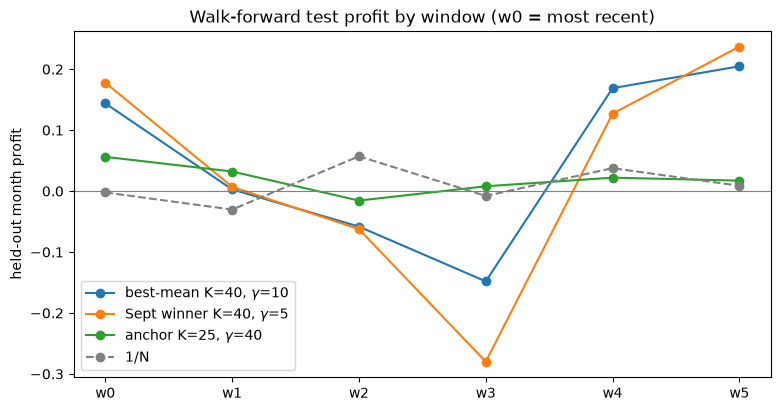

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.5))
series = [(f"best-mean K={int(best.K)}, $\\gamma$={best.gamma:g}", best),
          ("Sept winner K=40, $\\gamma$=5", row_of(40, 5)),
          ("anchor K=25, $\\gamma$=40", row_of(25, 40))]
for label, r in series:
    if r is None:
        continue
    ax.plot(labels, [r[lbl] for lbl in labels], marker="o", label=label)
ax.plot(labels, bench_profits, marker="o", ls="--", color="gray", label="1/N")
ax.axhline(0, color="gray", lw=0.8)
ax.set_ylabel("held-out month profit")
ax.set_title("Walk-forward test profit by window (w0 = most recent)")
ax.legend()
plt.show()

## Heatmaps over the $(\gamma, K)$ grid (across-window statistics)

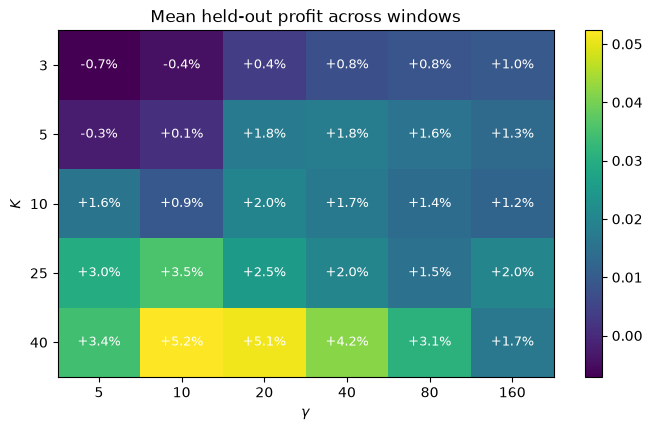

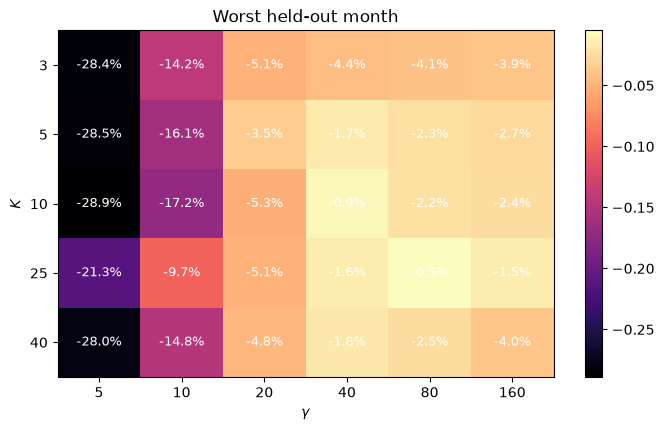

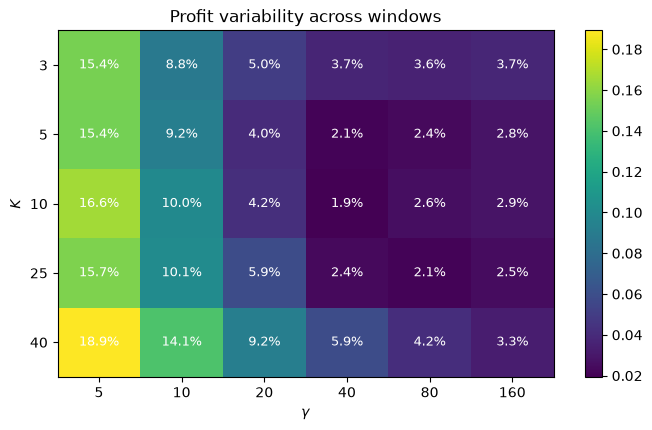

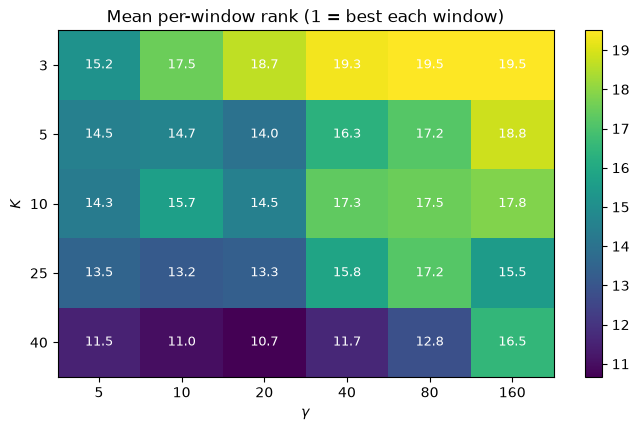

In [7]:
def heatmap(metric, title, fmt="{:+.1%}", cmap="viridis"):
    pivot = wf.pivot(index="K", columns="gamma", values=metric)[GAMMAS]
    pivot = pivot.loc[[k for k in KS if k in pivot.index]]
    fig, ax = plt.subplots(figsize=(8, 4.5))
    im = ax.imshow(pivot.to_numpy(), cmap=cmap, aspect="auto")
    ax.set_xticks(range(len(pivot.columns)), [f"{c:g}" for c in pivot.columns])
    ax.set_yticks(range(len(pivot.index)), [f"{i:g}" for i in pivot.index])
    ax.set_xlabel(r"$\gamma$")
    ax.set_ylabel("$K$")
    for i in range(pivot.shape[0]):
        for j in range(pivot.shape[1]):
            ax.text(j, i, fmt.format(pivot.to_numpy()[i, j]),
                    ha="center", va="center", color="white", fontsize=9)
    ax.set_title(title)
    fig.colorbar(im, ax=ax)
    return fig

heatmap("mean", "Mean held-out profit across windows")
heatmap("min", "Worst held-out month", cmap="magma")
heatmap("std", "Profit variability across windows", fmt="{:.1%}")
heatmap("mean_rank", "Mean per-window rank (1 = best each window)", fmt="{:.1f}")
plt.show()

## Honest caveats

- **Windows overlap.** Adjacent windows share 2 of 3 training months and are 1 month apart,
  so the 6 test months are disjoint but the configs fitted on them are correlated — this is
  not 6 independent replications.
- **Hindsight selection again.** Picking the best mean-across-windows config is still
  selection on the same data that produced it; the honest use is spotting *unstable* regions
  of the grid, not certifying a winner.
- **Regime dependence.** 6 months is one macro regime; a config that survived them may still
  fail in the next one.
- 1/N remains the reference: if the chosen config's mean is not comfortably above 1/N's, the
  $\hat\mu$ machinery is not paying for itself.
- Production rerun (fits on the **latest** 3 months, window 0's training data):
  `stonks portfolio --top-n 500 --months 3 --gamma G -k K --n-restarts 30 --lr 0.005`.